# 02 - OCR with PaddleOCR

**Goal:** Extract text, bounding boxes, and confidence scores from receipt images

**What you'll learn:**
1. How PaddleOCR works (detection → recognition)
2. Understanding bounding boxes and coordinates
3. Confidence scores and what they mean
4. Saving raw OCR output for debugging

> **Key insight:** Always save raw OCR output. You'll need it when extraction rules fail.

## Setup

In [11]:
from paddleocr import PaddleOCR
import cv2
import numpy as np
from PIL import Image
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import json
import os

%matplotlib inline

# Paths
IMAGES_DIR = Path("../images")
OUT_DIR = Path("../out")

# Suppress paddle logs and version check
os.environ['PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK'] = 'True'

## Step 1: Initialize PaddleOCR

**Key parameters (PaddleOCR v3.x):**
- `use_textline_orientation=True` - Detects rotated text
- `lang='en'` - English language model

In [12]:
# Initialize OCR engine
# First run will download the model (~150MB)
ocr = PaddleOCR(
    use_textline_orientation=True,  # Detect rotated text (v3.x API)
    lang='en'                        # English model
)

print("✅ PaddleOCR initialized")

Creating model: ('PP-LCNet_x1_0_doc_ori', None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/Users/jeffersonqiu/.paddlex/official_models/PP-LCNet_x1_0_doc_ori`.
Creating model: ('UVDoc', None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/Users/jeffersonqiu/.paddlex/official_models/UVDoc`.
Creating model: ('PP-LCNet_x1_0_textline_ori', None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/Users/jeffersonqiu/.paddlex/official_models/PP-LCNet_x1_0_textline_ori`.
Creating model: ('PP-OCRv5_server_det', None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/Users/jeffersonqiu/.paddlex/official_models/PP-OCRv5_server_det`.
Creating model: ('en_PP-OCRv5_mobile_rec', None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/Use

✅ PaddleOCR initialized


## Step 2: Load a Receipt Image

We can use either:
- Original image from `images/`
- Preprocessed image from `out/`

PaddleOCR accepts both file paths and numpy arrays.

In [13]:
# Find images
image_files = list(IMAGES_DIR.glob("*.[jJpP][pPnN][gG]*")) + list(IMAGES_DIR.glob("*.webp"))
print(f"Found {len(image_files)} images in images/")

# Also check for preprocessed images
preprocessed_files = list(OUT_DIR.glob("preprocessed_*.png"))
print(f"Found {len(preprocessed_files)} preprocessed images in out/")

if image_files:
    # Use original image (PaddleOCR handles preprocessing internally too)
    image_path = image_files[0]
    print(f"\nUsing: {image_path.name}")
else:
    print("\n⚠️  No images found! Add a receipt to images/ folder.")

Found 1 images in images/
Found 1 preprocessed images in out/

Using: receipt-ocr-original.jpg


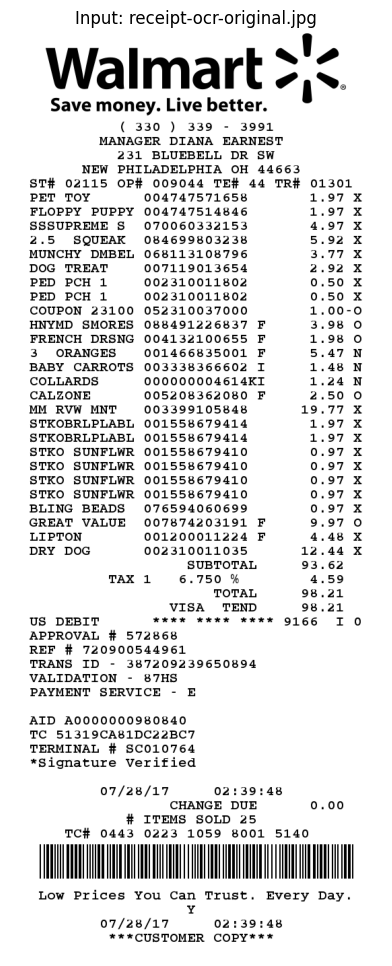

In [14]:
# Display the image
if image_files:
    img = cv2.imread(str(image_path))
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    plt.figure(figsize=(8, 12))
    plt.imshow(img_rgb)
    plt.title(f"Input: {image_path.name}")
    plt.axis('off')
    plt.show()

## Step 3: Run OCR

PaddleOCR returns a list of results. Each result contains:
- **Bounding box**: 4 corner points `[[x1,y1], [x2,y2], [x3,y3], [x4,y4]]`
- **Text**: The recognized string
- **Confidence**: 0-1 score (1 = very confident)

In [15]:
# Run OCR
results = ocr.predict(str(image_path))

# results is a list of pages (usually just 1 for single image)
# Each page contains a list of detected text regions
print(f"Number of results: {len(results)}")

Number of results: 1


## Step 4: Understand the Output Structure

Let's examine what PaddleOCR returns.

In [16]:
# Look at first 5 results
# PaddleOCR v3.x returns dict with 'rec_texts', 'rec_scores', 'dt_polys'
if results:
    result = results[0]
    print("Sample OCR results (first 5 lines):\n")
    for i in range(min(5, len(result['rec_texts']))):
        text = result['rec_texts'][i]
        confidence = result['rec_scores'][i]
        bbox = result['dt_polys'][i]  # 4 corner points
        
        print(f"Line {i+1}:")
        print(f"  Text: '{text}'")
        print(f"  Confidence: {confidence:.3f}")
        print(f"  Bounding box: {bbox.tolist() if hasattr(bbox, 'tolist') else bbox}")
        print()

Sample OCR results (first 5 lines):

Line 1:
  Text: 'Walmart'
  Confidence: 0.998
  Bounding box: [[34, 0], [406, 0], [406, 75], [33, 73]]

Line 2:
  Text: '@'
  Confidence: 0.994
  Bounding box: [[527, 42], [541, 42], [541, 55], [527, 55]]

Line 3:
  Text: 'Save money. Live better.'
  Confidence: 1.000
  Bounding box: [[40, 71], [405, 73], [405, 111], [40, 109]]

Line 4:
  Text: '('
  Confidence: 0.879
  Bounding box: [[158, 119], [177, 119], [177, 136], [158, 136]]

Line 5:
  Text: '330'
  Confidence: 1.000
  Bounding box: [[180, 117], [226, 117], [226, 136], [180, 136]]



## Step 5: Parse OCR Results into Clean Format

Let's create a structured representation of the OCR output.

In [17]:
def parse_ocr_results(results):
    """
    Parse PaddleOCR v3.x results into a clean list of dictionaries.
    
    Returns:
        List of dicts with: text, confidence, bbox (x1,y1,x2,y2), center_y
    """
    parsed = []
    
    if not results:
        return parsed
    
    result = results[0]  # First page
    texts = result['rec_texts']
    scores = result['rec_scores']
    polys = result['dt_polys']
    
    for i in range(len(texts)):
        bbox_points = polys[i]  # 4 corner points
        text = texts[i]
        confidence = scores[i]
        
        # Convert to simple bounding box (x1, y1, x2, y2)
        if hasattr(bbox_points, 'tolist'):
            bbox_points = bbox_points.tolist()
        x_coords = [p[0] for p in bbox_points]
        y_coords = [p[1] for p in bbox_points]
        
        x1, x2 = min(x_coords), max(x_coords)
        y1, y2 = min(y_coords), max(y_coords)
        
        # Center Y is useful for grouping lines
        center_y = (y1 + y2) / 2
        
        parsed.append({
            'text': text,
            'confidence': round(float(confidence), 3),
            'bbox': [round(x1), round(y1), round(x2), round(y2)],
            'center_y': round(center_y)
        })
    
    # Sort by Y coordinate (top to bottom)
    parsed.sort(key=lambda x: x['center_y'])
    
    return parsed

# Parse our results
parsed_results = parse_ocr_results(results)
print(f"Parsed {len(parsed_results)} text regions")

Parsed 188 text regions


In [18]:
# Display all parsed results
print("All detected text (top to bottom):\n")
print(f"{'#':<3} {'Y':>5} {'Conf':>6}  Text")
print("-" * 60)

for i, item in enumerate(parsed_results):
    print(f"{i+1:<3} {item['center_y']:>5} {item['confidence']:>6.3f}  {item['text']}")

All detected text (top to bottom):

#       Y   Conf  Text
------------------------------------------------------------
1      38  0.998  Walmart
2      48  0.994  @
3      91  1.000  Save money. Live better.
4     124  1.000  3991
5     125  0.947  -
6     126  1.000  330
7     126  0.305  ∞
8     126  1.000  339
9     128  0.879  (
10    148  0.997  DIANA EARNEST
11    150  1.000  MANAGER
12    170  0.998  231 BLUEBELL DR SW
13    192  0.998  PHILADELPHIA OH 44663
14    196  1.000  NEW
15    209  1.000  01301
16    211  0.999  ST#
17    214  1.000  44 TR#
18    216  1.000  02115
19    216  0.998  TE#
20    217  0.999  009044
21    218  0.998  OP#
22    230  0.413  7
23    232  1.000  1.97
24    234  1.000  PET
25    238  1.000  TOY
26    238  1.000  004747571658
27    255  1.000  1.97
28    258  1.000  FLOPPY
29    260  1.000  004747514846
30    261  1.000  PUPPY
31    278  1.000  4.97
32    280  0.987  SSSUPREME S
33    282  1.000  070060332153
34    300  1.000  2.5
35    300  1.000

## Step 6: Visualize OCR Results

Draw bounding boxes on the image to see what OCR detected.

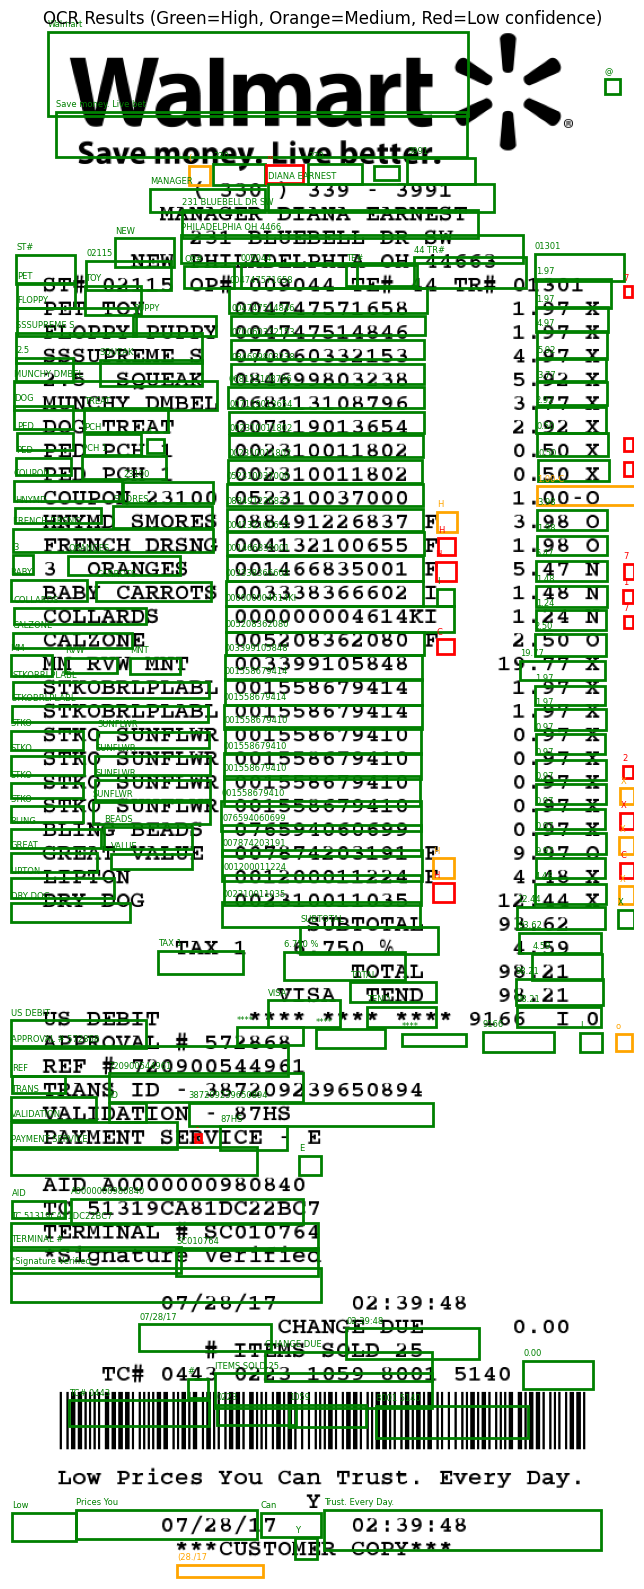

In [19]:
def visualize_ocr(image_path, parsed_results, figsize=(12, 16)):
    """
    Draw bounding boxes and text on the image.
    """
    # Load image
    img = cv2.imread(str(image_path))
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    fig, ax = plt.subplots(1, 1, figsize=figsize)
    ax.imshow(img_rgb)
    
    # Draw each bounding box
    for item in parsed_results:
        x1, y1, x2, y2 = item['bbox']
        width = x2 - x1
        height = y2 - y1
        
        # Color based on confidence
        if item['confidence'] > 0.9:
            color = 'green'
        elif item['confidence'] > 0.7:
            color = 'orange'
        else:
            color = 'red'
        
        # Draw rectangle
        rect = patches.Rectangle(
            (x1, y1), width, height,
            linewidth=2, edgecolor=color, facecolor='none'
        )
        ax.add_patch(rect)
        
        # Add text label (small font)
        ax.text(x1, y1 - 5, item['text'][:20], fontsize=6, color=color)
    
    ax.set_title("OCR Results (Green=High, Orange=Medium, Red=Low confidence)")
    ax.axis('off')
    plt.tight_layout()
    plt.show()

# Visualize
if image_files:
    visualize_ocr(image_path, parsed_results)

## Step 7: Save Raw OCR Output (Important for Debugging!)

Always save the raw OCR output. When extraction rules fail, you'll want to inspect what OCR actually detected.

In [22]:
def save_ocr_results(parsed_results, image_path, output_dir):
    """
    Save OCR results as JSON for debugging.
    """
    output_path = Path(output_dir) / f"ocr_{Path(image_path).stem}.json"
    
    data = {
        'source_image': str(image_path),
        'num_regions': len(parsed_results),
        'results': parsed_results
    }
    
    with open(output_path, 'w') as f:
        json.dump(data, f, indent=2)
    
    print(f"✅ Saved OCR results to: {output_path}")
    return output_path

# Save results
if parsed_results:
    save_ocr_results(parsed_results, image_path, OUT_DIR)

✅ Saved OCR results to: ../out/ocr_receipt-ocr-original.json


In [23]:
parsed_results

[{'text': 'Walmart',
  'confidence': 0.998,
  'bbox': [33, 0, 406, 75],
  'center_y': 38},
 {'text': '@',
  'confidence': 0.994,
  'bbox': [527, 42, 541, 55],
  'center_y': 48},
 {'text': 'Save money. Live better.',
  'confidence': 1.0,
  'bbox': [40, 71, 405, 111],
  'center_y': 91},
 {'text': '3991',
  'confidence': 1.0,
  'bbox': [352, 112, 412, 135],
  'center_y': 124},
 {'text': '-',
  'confidence': 0.947,
  'bbox': [322, 119, 345, 131],
  'center_y': 125},
 {'text': '330',
  'confidence': 1.0,
  'bbox': [180, 117, 226, 136],
  'center_y': 126},
 {'text': '∞',
  'confidence': 0.305,
  'bbox': [227, 118, 259, 134],
  'center_y': 126},
 {'text': '339',
  'confidence': 1.0,
  'bbox': [264, 117, 312, 135],
  'center_y': 126},
 {'text': '(',
  'confidence': 0.879,
  'bbox': [158, 119, 177, 136],
  'center_y': 128},
 {'text': 'DIANA EARNEST',
  'confidence': 0.997,
  'bbox': [228, 135, 429, 160],
  'center_y': 148},
 {'text': 'MANAGER',
  'confidence': 1.0,
  'bbox': [124, 139, 226, 160

## Step 8: Complete OCR Function

Here's the complete function we'll convert to a module later.

In [21]:
class ReceiptOCR:
    """
    OCR wrapper for receipt images (PaddleOCR v3.x).
    
    Usage:
        ocr = ReceiptOCR()
        results = ocr.process("path/to/receipt.jpg")
    """
    
    def __init__(self, lang='en'):
        self.engine = PaddleOCR(
            use_textline_orientation=True,
            lang=lang
        )
    
    def process(self, image_path):
        """
        Run OCR on an image and return parsed results.
        
        Returns:
            List of dicts with: text, confidence, bbox, center_y
        """
        results = self.engine.predict(str(image_path))
        return self._parse_results(results)
    
    def _parse_results(self, results):
        """Parse raw PaddleOCR v3.x output into clean format."""
        parsed = []
        
        if not results:
            return parsed
        
        result = results[0]
        texts = result['rec_texts']
        scores = result['rec_scores']
        polys = result['dt_polys']
        
        for i in range(len(texts)):
            bbox_points = polys[i]
            if hasattr(bbox_points, 'tolist'):
                bbox_points = bbox_points.tolist()
            
            x_coords = [p[0] for p in bbox_points]
            y_coords = [p[1] for p in bbox_points]
            
            x1, x2 = min(x_coords), max(x_coords)
            y1, y2 = min(y_coords), max(y_coords)
            center_y = (y1 + y2) / 2
            
            parsed.append({
                'text': texts[i],
                'confidence': round(float(scores[i]), 3),
                'bbox': [round(x1), round(y1), round(x2), round(y2)],
                'center_y': round(center_y)
            })
        
        parsed.sort(key=lambda x: x['center_y'])
        return parsed

# Test the class
if image_files:
    receipt_ocr = ReceiptOCR()
    test_results = receipt_ocr.process(image_path)
    print(f"✅ ReceiptOCR class works! Detected {len(test_results)} text regions")

Creating model: ('PP-LCNet_x1_0_doc_ori', None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/Users/jeffersonqiu/.paddlex/official_models/PP-LCNet_x1_0_doc_ori`.
Creating model: ('UVDoc', None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/Users/jeffersonqiu/.paddlex/official_models/UVDoc`.
Creating model: ('PP-LCNet_x1_0_textline_ori', None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/Users/jeffersonqiu/.paddlex/official_models/PP-LCNet_x1_0_textline_ori`.
Creating model: ('PP-OCRv5_server_det', None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/Users/jeffersonqiu/.paddlex/official_models/PP-OCRv5_server_det`.
Creating model: ('en_PP-OCRv5_mobile_rec', None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/Use

✅ ReceiptOCR class works! Detected 188 text regions


---

## 🎯 Key Takeaways

1. **PaddleOCR returns bounding boxes** - 4 corner points per text region
2. **Confidence scores** help filter unreliable detections
3. **Y-coordinate sorting** gives us top-to-bottom reading order
4. **Always save raw OCR output** for debugging extraction failures

## ➡️ Next: `03_extraction.ipynb`

In the next notebook, we'll extract structured data (vendor, date, total, items) from the OCR output.